# Diabetic Retinopathy Classification: Data Exploration, Preprocessing, and CNN Modeling

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from torch.utils.data import DataLoader, Dataset
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold
import matplotlib.pyplot as plt
import random
from collections import Counter
import albumentations as A
import cv2
from torchvision import transforms
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import WeightedRandomSampler
import torch
from torch.optim import Adam
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
import seaborn as sns

In [2]:
dirname = Path("/kaggle/input/datasets/vladdraghici/is-2026-set-a-v2/sl2026-retina-set-a/")
labels_path = dirname.joinpath("labels.csv")
labels = pd.read_csv(labels_path)
image_paths = labels["image"]

In [3]:
class Data(Dataset):
    def __init__(self, path, indices=None, transform=None):
        self.path = path
        self.images = pd.read_csv(self.path.joinpath("labels.csv"))
        self.transform = transform
        if indices is not None:
            self.images = self.images.iloc[indices, :]
            self.images = self.images.reset_index(drop=True)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image_path = self.images.loc[idx, "image"]
        image_label = self.images.loc[idx, "label"]
        image = Image.open(self.path.joinpath(image_path))

        if self.transform:
            image = self.transform(image)

        return image, image_label

In [4]:
sgkf = StratifiedGroupKFold(n_splits=10, random_state=42, shuffle=True)
indices = list(range(0, 10000))
targets = labels["label"]
groups = labels["group"]

splits = sgkf.split(indices, targets, groups)
fold_indices = []

for i, (_, test_index) in enumerate(sgkf.split(indices, targets, groups)):
    fold_indices.append(test_index)

train_ids = np.concatenate(fold_indices[:8])
val_ids = fold_indices[8]
test_ids = fold_indices[9]

### Training Class Imbalance

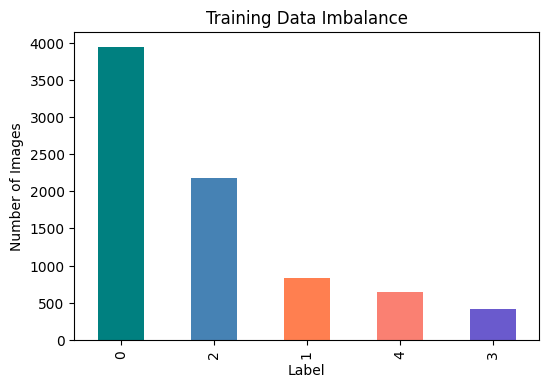

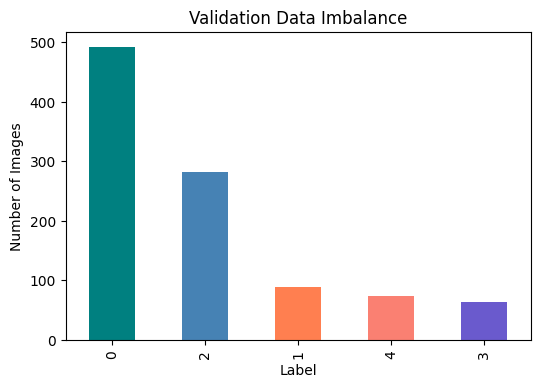

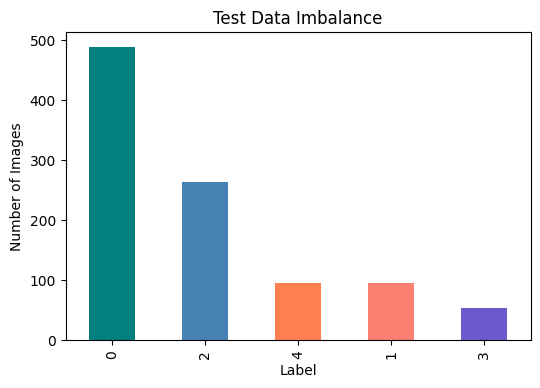

In [5]:
for title, ids in zip(["Training", "Validation", "Test"], [train_ids, val_ids, test_ids]):
    diabetes_counts = targets[ids].value_counts()
    plt.figure(figsize=(6, 4))
    diabetes_counts.plot(kind='bar', color=["teal", "steelblue", "coral", "salmon", "slateblue"])
    plt.title(title + " Data Imbalance")
    plt.ylabel('Number of Images')
    plt.xlabel('Label')
    plt.show()

The class distributions in the training, validation, and test splits are imbalanced. Class 0 is the most represented, while classes 1, 3, and 4 each have approximately one fifth as many examples as class 0. Class 2 has approximately half as many examples as class 0. The similar distributions across the three splits suggest that stratification preserved the original class proportions. The class imbalance could be addressed by oversampling the minority classes, either through augmentation or by bootstrapping, or by applying class weights during training.

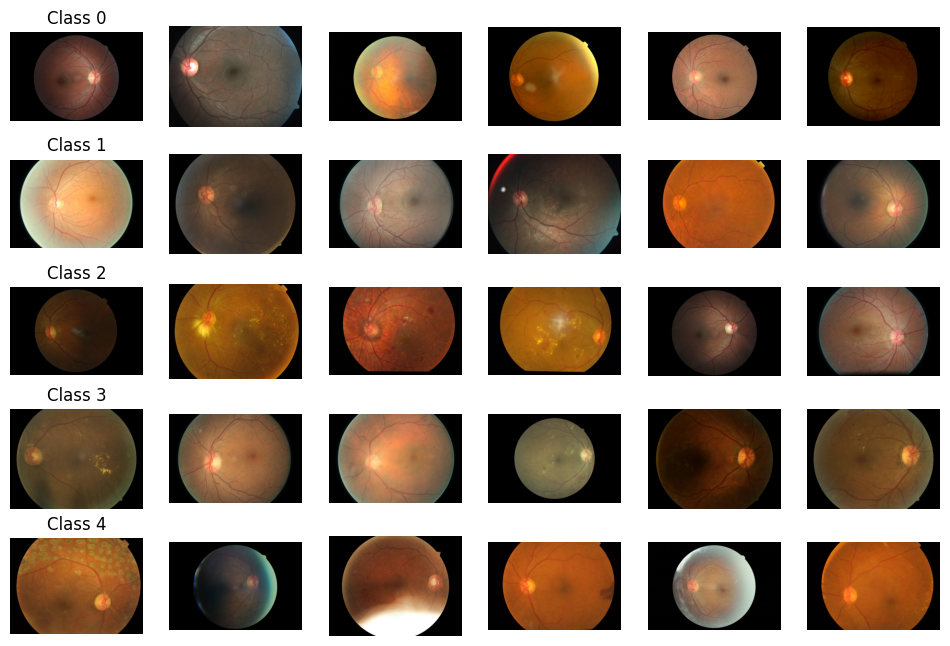

In [6]:
fig = plt.figure(figsize=(12, 8))

for target in range(5):
    images = labels.loc[labels["label"] == target, "image"].sample(6)

    for i, image in enumerate(images):
        fig.add_subplot(5, 6, target * 6 + i + 1)
        plt.imshow(Image.open(dirname.joinpath(image)))
        plt.axis(False)

        if i == 0:
            plt.title(f"Class {target}")

All classes show a great deal of variability in terms of brightness, color and clarity. Although images in class 0 tend to exhibit a clearer aspect, the images in neighbouring classes do not present a clear visual boundary. At the size of this display, images from different classes can look similar.

In [7]:
modes = Counter()
sizes = Counter()
need_normalizing = Counter()

for image_path in image_paths:
    with Image.open(dirname.joinpath(image_path)) as image:
        modes[image.mode] += 1
        sizes[image.size] += 1
        extreme_values = image.getextrema()
        for i in range(3):
            if extreme_values[i][0] < 0 or extreme_values[i][1] > 255:
                need_normalizing[i] += 1

mode_table = pd.DataFrame(
    [{"Mode": mode, "Images": count}
     for mode, count in modes.most_common(5)]
)

size_table = pd.DataFrame(
    [{"Width": width, "Height": height, "Images": count}
     for (width, height), count in sizes.most_common(5)]
)

display(mode_table)
display(size_table)

if not need_normalizing:
    print("Pixels values are in the range of [0, 255].")
else:
    print("Pixel values need normalizing.")

,Mode,Images
0,RGB,10000


,Width,Height,Images
0,512,341,4206
1,512,384,2040
2,512,512,975
3,512,340,911
4,512,368,638


Pixels values are in the range of [0, 255].


All 10000 images are in an RGB mode. The sizes of the images have a range of different values, the most common among them being (512, 341), followed by (512, 384). Therefore, the images will have to be scaled. For this process I chose the values (384, 384) as a tradeoff between detail and computational cost. All images are stored as RGB images with pixel values in the range [0, 255]. This confirms that their original pixel ranges are consistent.

In [6]:
def ben_graham(img, sigma=10):
    rgb = np.array(img.convert("RGB")) if isinstance(img, Image.Image) else img
    blur = cv2.GaussianBlur(rgb, (0, 0), sigma)
    return Image.fromarray(cv2.addWeighted(rgb, 4, blur, -4, 128))

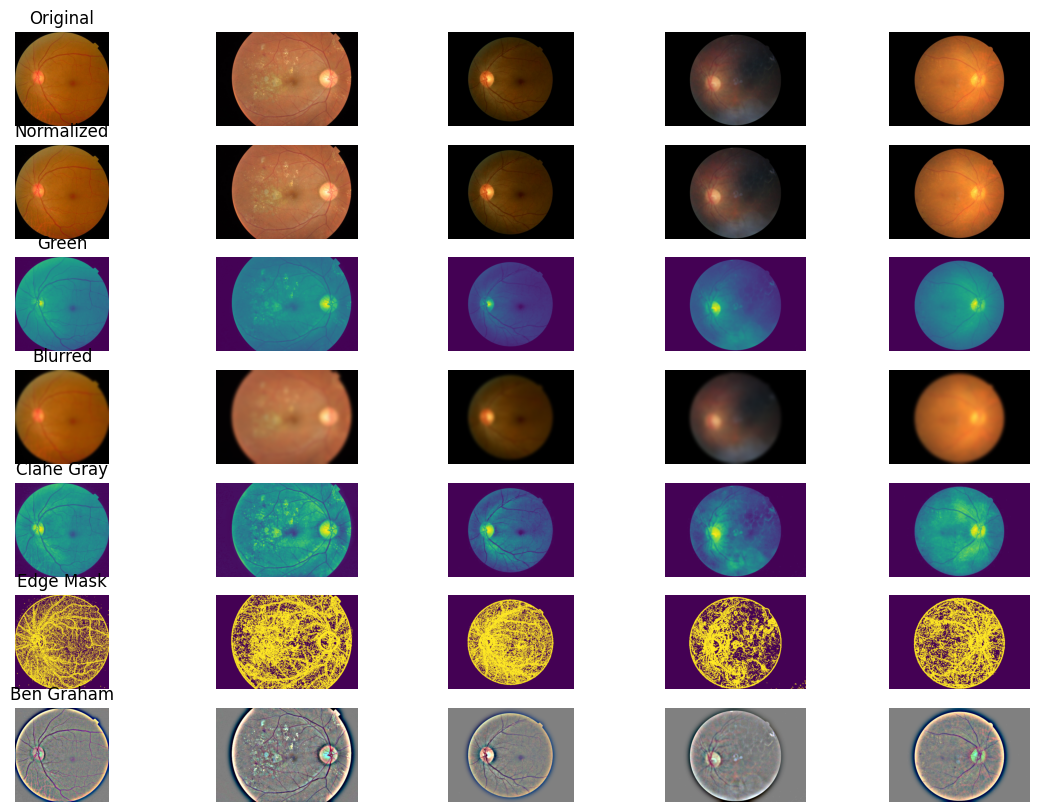

In [8]:
fig = plt.figure(figsize=(14, 10))

for idx, image_path in enumerate(image_paths[:5]):
    with Image.open(dirname.joinpath(image_path)) as image:
        rgb = np.array(image.convert("RGB"))
    
    normalized = rgb.astype(np.float32) / 255.0
    
    green = rgb[:, :, 1]
    
    blurred = cv2.GaussianBlur(rgb, (35, 35), 0)
    
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    
    clahe_gray = A.CLAHE(p=1.0)(image=gray)["image"]
    
    sobelx = cv2.Sobel(clahe_gray, cv2.CV_64F, 1, 0, ksize=5)
    sobely = cv2.Sobel(clahe_gray, cv2.CV_64F, 0, 1, ksize=5)
    
    edges = cv2.magnitude(sobelx, sobely)
    edges = cv2.normalize(
        edges, None, 0, 255, cv2.NORM_MINMAX
    ).astype(np.uint8)
    
    _, edge_mask = cv2.threshold(edges, 10, 255, cv2.THRESH_BINARY)

    ben_graham_img = ben_graham(rgb)

    for i, img, title in zip(list(range(7)),[rgb, normalized, green, blurred, clahe_gray, edge_mask, ben_graham_img], ["Original", "Normalized", "Green", "Blurred", "Clahe Gray", "Edge Mask", "Ben Graham"]):
        fig.add_subplot(7, 5, i * 5 + idx + 1)
        plt.imshow(img)
        plt.axis(False)

        if idx == 0:
            plt.title(title)

- **Pixel normalization:** Scales pixel values to make them easier for the model to process. The image looks almost the same, but its pixel values range from 0 to 1.
- **Green channel:** Shows only the green part of the image to check whether blood vessels and other retinal details are easier to see. The original colors are lost.
- **Gaussian filter:** Blurs the image to smooth small variations and reduce noise. It can also blur small lesions.
- **CLAHE:** Increases contrast in local areas so that less visible details may stand out more. It can also make noise more noticeable.
- **Sobel and thresholding:** Highlights sharp changes in brightness, such as the edges of blood vessels. The result is a black-and-white edge mask rather than a normal color image.
- **Ben Graham preprocessing:** This operation subtracts a heavily blurred version of the image from the original and adjusts the result to enhance local contrast. It can reduce uneven background illumination and make retinal details more visible, but may also amplify noise. In the current training pipeline, it is applied to the training, validation, and test images.

## Training Pipeline

Ben Graham preprocessing, resizing, tensor conversion, and normalization are applied to the training, validation, and test images. Random horizontal flips, vertical flips, and rotations are applied only to training images to provide additional variation during training. Validation and test images use only the deterministic preprocessing steps.

In [10]:
preprocess = transforms.Compose([
    transforms.Lambda(ben_graham),
    transforms.Resize((384, 384)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

train_augmentation = transforms.Compose([
    transforms.Lambda(ben_graham),
    transforms.Resize((384, 384)),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=45, fill=(128, 128, 128)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

train_dataset = Data(path=dirname, indices=train_ids, transform=train_augmentation)
val_dataset = Data(path=dirname, indices=val_ids, transform=preprocess)
test_dataset = Data(path=dirname, indices=test_ids, transform=preprocess)

In [11]:
train_labels = train_dataset.images["label"]
class_counts = train_labels.value_counts()

weights = []

for label in train_labels:
    weights.append(1.0 / class_counts[label])

train_sampler = WeightedRandomSampler(
    weights=torch.as_tensor(weights, dtype=torch.double),
    num_samples=len(weights),
    replacement=True
)

In [12]:
batch_size = 32
num_workers = 0

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    sampler=train_sampler,
    shuffle=False,
    num_workers=num_workers
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers
)

The neural network architecture uses 5 convolutional layers, with 32, 64, 128, 128 and 256 filters respectively. All of them are followed by batch normalization, a ReLU activation and max pooling. Before flattening the input, adaptive max pooling is applied, which reduces each feature map to a single value. Then, a fully connected layer with 64 units was used, followed by a ReLU activation and a dropout layer, in order to mitigate overfitting, and a final fully connected layer, with the output size corresponding to the number of classes.

In [13]:
class ClassificationCNN(nn.Module):
    def __init__(self, in_size, out_size):
        super(ClassificationCNN, self).__init__()
        self.conv1 = nn.Conv2d(in_size, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.conv4 = nn.Conv2d(128, 128, kernel_size=3, padding=1)
        self.conv5 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.batch_norm1 = nn.BatchNorm2d(32)
        self.batch_norm2 = nn.BatchNorm2d(64)
        self.batch_norm3 = nn.BatchNorm2d(128)
        self.batch_norm4 = nn.BatchNorm2d(128)
        self.batch_norm5 = nn.BatchNorm2d(256)
        self.pool = nn.MaxPool2d(kernel_size=2)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.3)
        self.adaptive_pool = nn.AdaptiveMaxPool2d((1, 1))
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(256, 64)
        self.fc2 = nn.Linear(64, out_size)

    def forward(self, x):
        x = self.conv1(x)
        x = self.batch_norm1(x)
        x = self.relu(x)
        x = self.pool(x)

        x = self.conv2(x)
        x = self.batch_norm2(x)
        x = self.relu(x)
        x = self.pool(x)

        x = self.conv3(x)
        x = self.batch_norm3(x)
        x = self.relu(x)
        x = self.pool(x)

        x = self.conv4(x)
        x = self.batch_norm4(x)
        x = self.relu(x)
        x = self.pool(x)

        x = self.conv5(x)
        x = self.batch_norm5(x)
        x = self.relu(x)
        x = self.pool(x)

        x = self.adaptive_pool(x)
        x = self.flatten(x)

        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)
        return x

In [22]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = ClassificationCNN(3, 5).to(device)
print(device)

cuda


The model is trained for 40 epochs using the cross-entropy loss, which is the standard choice for multi-class classification. Class imbalance was handled in the data loader with a weighted sampler rather than in the loss. This makes the class distribution more balanced across the sampled training data on average. The optimizer is AdamW with a learning rate of 3e-4 and a weight decay of 1e-4, combined with a cosine annealing schedule that gradually reduces the learning rate towards zero over the 40 epochs. After each epoch the model was evaluated on the validation set, and the weights with the best macro F1 score were saved and later used for testing, since macro F1 is more informative than accuracy on imbalanced data.

In [24]:
num_epochs = 40
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)

Epoch 1/40, Train Loss: 1.5728, Train Accuracy: 0.2676, Val Loss: 1.5632, Val Accuracy: 0.2707, Val F1: 0.1961
Epoch 2/40, Train Loss: 1.4980, Train Accuracy: 0.3242, Val Loss: 1.2623, Val Accuracy: 0.5025, Val F1: 0.3090
Epoch 3/40, Train Loss: 1.3888, Train Accuracy: 0.3789, Val Loss: 1.2598, Val Accuracy: 0.4376, Val F1: 0.3160
Epoch 4/40, Train Loss: 1.3428, Train Accuracy: 0.4073, Val Loss: 1.2012, Val Accuracy: 0.4585, Val F1: 0.3367
Epoch 5/40, Train Loss: 1.3074, Train Accuracy: 0.4200, Val Loss: 1.1795, Val Accuracy: 0.4486, Val F1: 0.3350
Epoch 6/40, Train Loss: 1.2828, Train Accuracy: 0.4363, Val Loss: 1.1570, Val Accuracy: 0.4845, Val F1: 0.3832
Epoch 7/40, Train Loss: 1.2585, Train Accuracy: 0.4409, Val Loss: 1.1384, Val Accuracy: 0.5425, Val F1: 0.4053
Epoch 8/40, Train Loss: 1.2177, Train Accuracy: 0.4621, Val Loss: 1.1962, Val Accuracy: 0.5255, Val F1: 0.3898
Epoch 9/40, Train Loss: 1.2050, Train Accuracy: 0.4693, Val Loss: 1.0408, Val Accuracy: 0.6044, Val F1: 0.4580
E

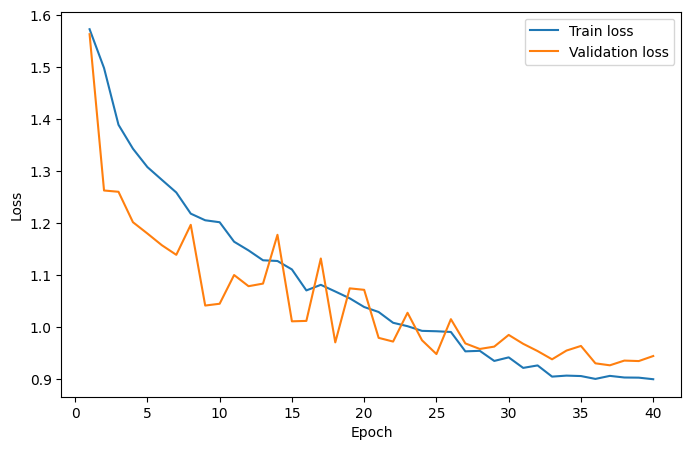

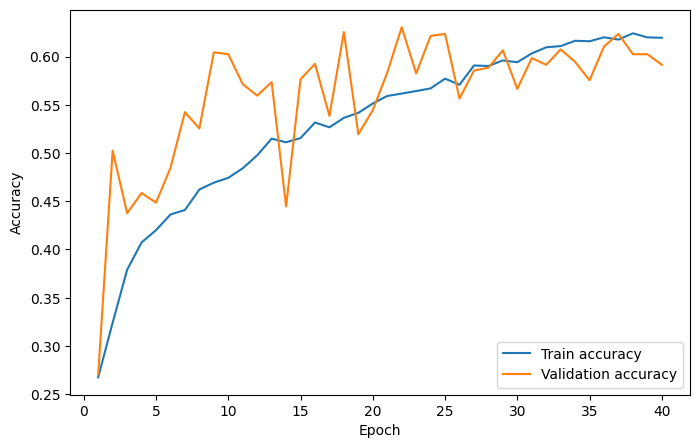

In [25]:
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []
best_val_f1 = 0.0

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    train_correct = 0
    train_total = 0

    for i, data in enumerate(train_loader, 0):
        inputs, targets = data
        inputs = inputs.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        batch_size = targets.size(0)
        running_loss += loss.item() * batch_size
        
        predicted_classes = torch.argmax(outputs, dim=1)
        correct_predictions = predicted_classes == targets
        train_correct += correct_predictions.sum().item()
        
        train_total += batch_size

    train_loss = running_loss / train_total
    train_accuracy = train_correct / train_total
    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0
    val_true = []
    val_pred = []

    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs = inputs.to(device)
            targets = targets.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, targets)

            batch_size = targets.size(0)
            val_loss_sum += loss.item() * batch_size
            
            predicted_classes = torch.argmax(outputs, dim=1)
            correct_predictions = predicted_classes == targets
            val_correct += correct_predictions.sum().item()
            
            val_total += batch_size

            val_true.extend(targets.cpu().tolist())
            val_pred.extend(predicted_classes.cpu().tolist())

    val_loss = val_loss_sum / val_total
    val_accuracy = val_correct / val_total
    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)
    val_f1 = f1_score(val_true, val_pred, average="macro", zero_division=0)

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        torch.save(model.state_dict(), "best_model.pth")

    print(
        f"Epoch {epoch + 1}/{num_epochs}, "
        f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.4f}, "
        f"Val Loss: {val_loss:.4f}, Val Accuracy: {val_accuracy:.4f}, "
        f"Val F1: {val_f1:.4f}"

    )
    scheduler.step()

print("Finished Training")

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_losses, label="Train loss")
plt.plot(epochs, val_losses, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_accuracies, label="Train accuracy")
plt.plot(epochs, val_accuracies, label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

Accuracy: 0.588
F1-macro: 0.496
              precision    recall  f1-score   support

     Class 0       0.82      0.74      0.78       489
     Class 1       0.25      0.51      0.34        95
     Class 2       0.60      0.32      0.42       263
     Class 3       0.27      0.58      0.37        53
     Class 4       0.54      0.60      0.57        95

    accuracy                           0.59       995
   macro avg       0.50      0.55      0.50       995
weighted avg       0.65      0.59      0.60       995



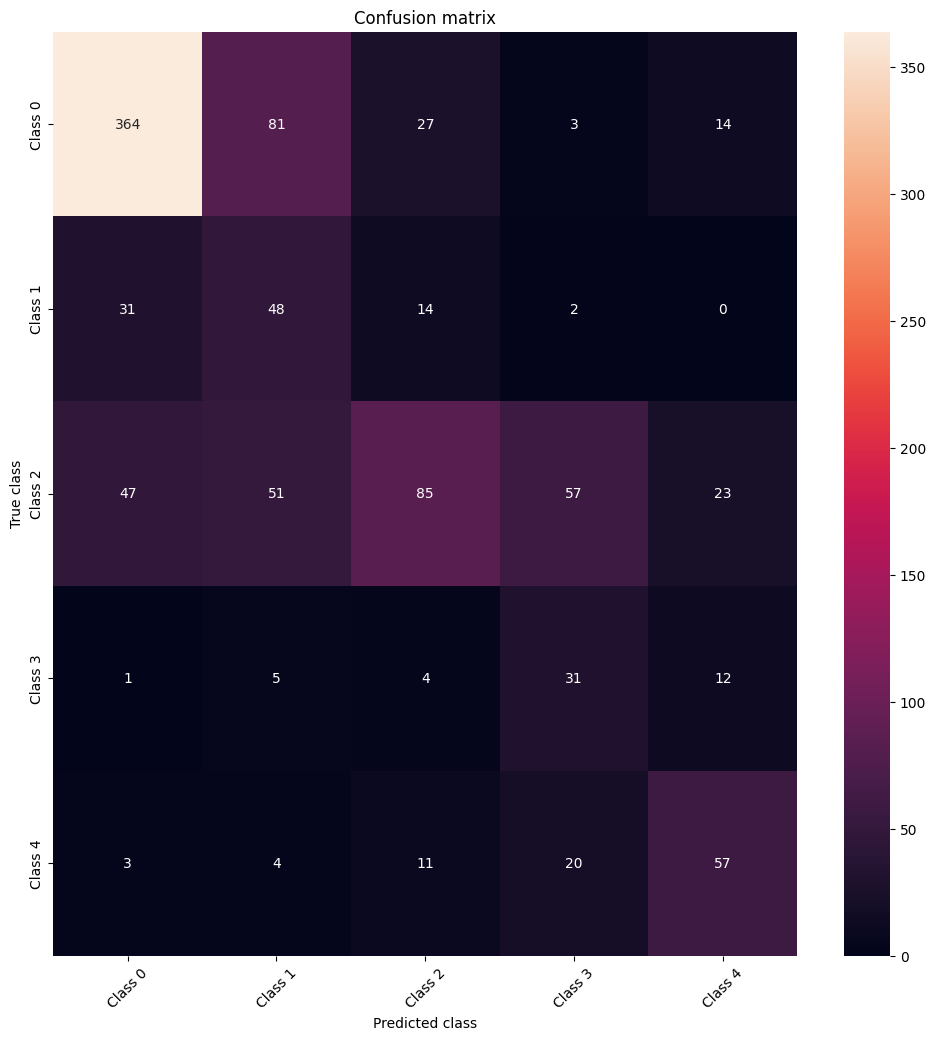

In [26]:
model.load_state_dict(torch.load("best_model.pth", map_location=device))
model.eval()

y = []
y_pred = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device)

        outputs = model(inputs)
        predictions = outputs.argmax(dim=1)

        y.extend(targets.cpu().tolist())
        y_pred.extend(predictions.cpu().tolist())

class_ids = list(range(5))
class_names = [f"Class {i}" for i in class_ids]

print(f"Accuracy: {accuracy_score(y, y_pred):.3f}")
print(f"F1-macro: {f1_score(y, y_pred, labels=class_ids, average='macro', zero_division=0):.3f}")
print(classification_report(
    y, y_pred, labels=class_ids,
    target_names=class_names, zero_division=0
))

cm = confusion_matrix(y, y_pred, labels=class_ids)

plt.figure(figsize=(12, 12))
sns.heatmap(cm, annot=True, fmt="d",
        xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Confusion matrix")
plt.xticks(rotation=45)
plt.show()

The test set contains 489 examples from the majority class out of 995, which is approximately 49.1%. A baseline model that always predicts the majority class would therefore achieve 49.1% accuracy on this test set. My model outperforms this baseline, achieving 58.8% accuracy.